# 05 · Classifying fish size (classification)

**Question:** can water quality and time place a pond-day's fish in one of five size classes, for ponds the model has not seen?

**Classes:** five size classes of daily fish weight. The thesis used **equal-width** bins (`pd.cut`), which is the main setting here; equal-frequency bins (`pd.qcut`) are run as a comparison. Because equal-width classes are imbalanced, models are compared on macro F1 and balanced accuracy rather than plain accuracy.

**Evaluation:** cross-validation grouped by pond (`GroupKFold`), so every test fold contains ponds the model never saw. A random row split would put readings from the same pond and day in both train and test and inflate the scores.

**Features:** daily mean temperature, dissolved oxygen, pH, nitrate, population and days since the pond's first record. Fish length is excluded: it is measured with weight on the same day and maps almost one-to-one to it, so it would leak the answer.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import importlib
import src.pond_pipeline
importlib.reload(src.pond_pipeline)  # pick up edits to src/ even if this kernel imported it earlier
from src.pond_pipeline import *  # noqa: F401,F403  (column names, thresholds, helpers)

# Raw pond CSVs live in data/raw/ (see data/README.md). Override with POND_RAW_DIR if needed.
RAW = Path(os.environ.get("POND_RAW_DIR", RAW_DIR))
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, roc_auc_score)
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

pond_day = pd.read_csv(PROCESSED_DIR / "pond_day.csv", parse_dates=["date"])
LABELS = ["very small", "small", "medium", "large", "very large"]
BINNING = os.environ.get("BINNING", "equal-width")  # thesis setting; "equal-frequency" for the comparison

def make_classes(weight, binning):
    if binning == "equal-width":
        return pd.cut(weight, bins=5, labels=False, retbins=True)
    return pd.qcut(weight, q=5, labels=False, retbins=True, duplicates="drop")

y, edges = make_classes(pond_day[WEIGHT], BINNING)
y = y.astype(int)
print(BINNING, "class edges (g):", np.round(edges, 1))
FEATURES = MODEL_SENSOR_COLS + [POPULATION, "days_since_start"]
X, groups = pond_day[FEATURES], pond_day["pond_id"]
cv = GroupKFold(n_splits=min(5, groups.nunique()))
y.value_counts().sort_index()

equal-width class edges (g): [   1.8  207.6  412.3  617.   821.7 1026.5]


Fish_Weight(g)
0    531
1    173
2     31
3    104
4     17
Name: count, dtype: int64

### Which processed data is used

Shows the file this notebook reads, when notebook 03 wrote it, and which version of the cleaning made it. If it warns, restart notebook 03's kernel and run it again.

In [3]:
check_processed(PROCESSED_DIR / "pond_day.csv")

file:     C:\Users\99451\OneDrivee\Desktop\pond_dataset\data\processed\pond_day.csv
written:  2026-11-25 14:04:38
made by:  2026-11-25.4 (dates per column, stale weights, pond 11 restock, DO 0.01-20)
src code: 2026-11-25.4 (dates per column, stale weights, pond 11 restock, DO 0.01-20)  (C:\Users\99451\OneDrivee\Desktop\pond_dataset\src\pond_pipeline.py)


,rows,first,last,max_weight
pond_id,,,,
1,81,2021-06-19,2021-10-13,318.640000
2,111,2021-06-19,2021-10-31,394.660000
3,76,2021-06-19,2021-10-12,294.920000
4,68,2021-06-19,2021-09-05,223.730000
6,89,2021-06-19,2021-10-13,304.760000
7,127,2021-06-18,2021-12-30,1026.457143
8,56,2021-06-18,2021-12-06,841.200000
9,101,2021-06-18,2021-10-13,431.200000
10,18,2021-06-25,2021-12-05,689.142900


In [4]:
models = {
    "Baseline: most frequent": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Decision tree (depth 6)": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=RANDOM_STATE),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced",
                                            random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": SafeXGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                                 colsample_bytree=0.8, random_state=RANDOM_STATE, eval_metric="mlogloss"),
}

results, probas = [], {}
classes = np.sort(y.unique())
for name, model in models.items():
    proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method="predict_proba")
    pred = classes[proba.argmax(axis=1)]
    probas[name] = proba
    results.append({"model": name,
                    "accuracy": accuracy_score(y, pred),
                    "balanced accuracy": balanced_accuracy_score(y, pred),
                    "macro F1": f1_score(y, pred, average="macro"),
                    "ROC AUC (OvR)": roc_auc_score(y, proba, multi_class="ovr", labels=classes)})
results = pd.DataFrame(results).set_index("model").sort_values("macro F1", ascending=False)
results.to_csv(RESULTS_DIR / f"classification_results_{BINNING}.csv")
results

,accuracy,balanced accuracy,macro F1,ROC AUC (OvR)
model,,,,
Logistic regression,0.858645,0.603867,0.586124,0.916654
Random forest,0.865654,0.582601,0.567279,0.933878
XGBoost,0.875000,0.544777,0.546661,0.944505
Decision tree (depth 6),0.876168,0.565375,0.541214,0.770757
Baseline: most frequent,0.620327,0.200000,0.153136,0.500000


## Equal-width vs equal-frequency bins

The same models with the other binning, for comparison. With equal-width bins most pond-days fall in the smallest class, so plain accuracy rewards predicting that class; compare macro F1 and balanced accuracy instead.

In [5]:
other = "equal-frequency" if BINNING == "equal-width" else "equal-width"
y_other = make_classes(pond_day[WEIGHT], other)[0].astype(int)
cls_other = np.sort(y_other.unique())
rows, probas_other = [], {}
for name, model in models.items():
    proba = cross_val_predict(model, X, y_other, groups=groups, cv=cv, method="predict_proba")
    probas_other[name] = proba
    pred = cls_other[proba.argmax(axis=1)]
    rows.append({"model": name, "binning": other, "accuracy": accuracy_score(y_other, pred),
                 "balanced accuracy": balanced_accuracy_score(y_other, pred),
                 "macro F1": f1_score(y_other, pred, average="macro"),
                 "ROC AUC (OvR)": roc_auc_score(y_other, proba, multi_class="ovr", labels=cls_other)})
other_results = pd.DataFrame(rows).set_index("model")
other_results.drop(columns="binning").to_csv(RESULTS_DIR / f"classification_results_{other}.csv")
comparison = pd.concat([results.assign(binning=BINNING).reset_index(), other_results.reset_index()])
comparison.pivot(index="model", columns="binning",
                 values=["macro F1", "balanced accuracy", "accuracy", "ROC AUC (OvR)"]).round(3)

macro F1             balanced accuracy  \
binning                 equal-frequency equal-width   equal-frequency   
model                                                                   
Baseline: most frequent           0.033       0.153             0.054   
Decision tree (depth 6)           0.774       0.541             0.772   
Logistic regression               0.742       0.586             0.743   
Random forest                     0.804       0.567             0.805   
XGBoost                           0.828       0.547             0.828   

                                           accuracy              \
binning                 equal-width equal-frequency equal-width   
model                                                             
Baseline: most frequent       0.200           0.054       0.620   
Decision tree (depth 6)       0.565           0.772       0.876   
Logistic regression           0.604           0.743       0.859   
Random forest                 0.583           0.805       0.866   
XGBoost                       0.545           0.828       0.875   

                          ROC AUC (OvR)              
binning                 equal-frequency equal-width  
model                                                
Baseline: most frequent           0.409       0.500  
Decision tree (depth 6)           0.880       0.771  
Logistic regression               0.934       0.917  
Random forest                     0.961       0.934  
XGBoost                           0.960       0.945

## Every model in detail

As in the thesis, each model gets a confusion matrix, a per-class report (precision, recall, F1) and ROC curves with AUC, for both binnings. All predictions are out-of-pond (`GroupKFold`). The most-frequent baseline is left out of the plots: it predicts one class only. Figures are saved to `results/figures/`, the per-class reports to `results/classification_report_<binning>.csv`.

In [6]:
from sklearn.metrics import precision_recall_fscore_support, roc_curve

FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
DETAIL_MODELS = [m for m in models if not m.startswith("Baseline")]
RUNS = {BINNING: (y, classes, probas), other: (y_other, cls_other, probas_other)}

def class_names(cls):
    return [LABELS[c] for c in cls] if len(cls) == len(LABELS) else [str(c) for c in cls]

def per_class_report(binning):
    yy, cls, pr = RUNS[binning]
    out = []
    for name in DETAIL_MODELS:
        pred = cls[pr[name].argmax(axis=1)]
        p, r, f, n = precision_recall_fscore_support(yy, pred, labels=cls, zero_division=0)
        aucs = [roc_auc_score(yy == c, pr[name][:, i]) for i, c in enumerate(cls)]
        out.append(pd.DataFrame({"model": name, "class": class_names(cls), "precision": p, "recall": r,
                                 "F1": f, "ROC AUC (one-vs-rest)": aucs, "pond-days": n}))
    out = pd.concat(out, ignore_index=True)
    out.to_csv(RESULTS_DIR / f"classification_report_{binning}.csv", index=False)
    return out.set_index(["model", "class"]).round(3)

def plot_confusion(binning):
    yy, cls, pr = RUNS[binning]
    names = class_names(cls)
    fig, axes = plt.subplots(1, len(DETAIL_MODELS), figsize=(5.2 * len(DETAIL_MODELS), 4.6))
    for ax, name in zip(axes, DETAIL_MODELS):
        cm = confusion_matrix(yy, cls[pr[name].argmax(axis=1)], labels=cls, normalize="true")
        sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
                    xticklabels=names, yticklabels=names, ax=ax)
        ax.set(title=name, xlabel="Predicted class", ylabel="True class" if ax is axes[0] else "")
    fig.suptitle(f"Confusion matrices, {binning} classes (row-normalised, unseen ponds)")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"confusion_matrices_{binning}.png", dpi=150, bbox_inches="tight")
    plt.show()

def plot_roc(binning):
    yy, cls, pr = RUNS[binning]
    names = class_names(cls)
    fig, axes = plt.subplots(1, len(DETAIL_MODELS), figsize=(5.2 * len(DETAIL_MODELS), 4.6), sharey=True)
    for ax, name in zip(axes, DETAIL_MODELS):
        for i, c in enumerate(cls):
            fpr, tpr, _ = roc_curve(yy == c, pr[name][:, i])
            ax.plot(fpr, tpr, label=f"{names[i]} ({roc_auc_score(yy == c, pr[name][:, i]):.2f})")
        ax.plot([0, 1], [0, 1], "k--", lw=0.8)
        macro = roc_auc_score(yy, pr[name], multi_class="ovr", labels=cls)
        ax.set(title=f"{name}\nmacro AUC {macro:.3f}", xlabel="False positive rate",
               ylabel="True positive rate" if ax is axes[0] else "")
        ax.legend(title="class (AUC)", fontsize=8, loc="lower right")
    fig.suptitle(f"ROC curves, one-vs-rest, {binning} classes (unseen ponds)")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"roc_curves_{binning}.png", dpi=150, bbox_inches="tight")
    plt.show()

### Equal-width classes (thesis setting)

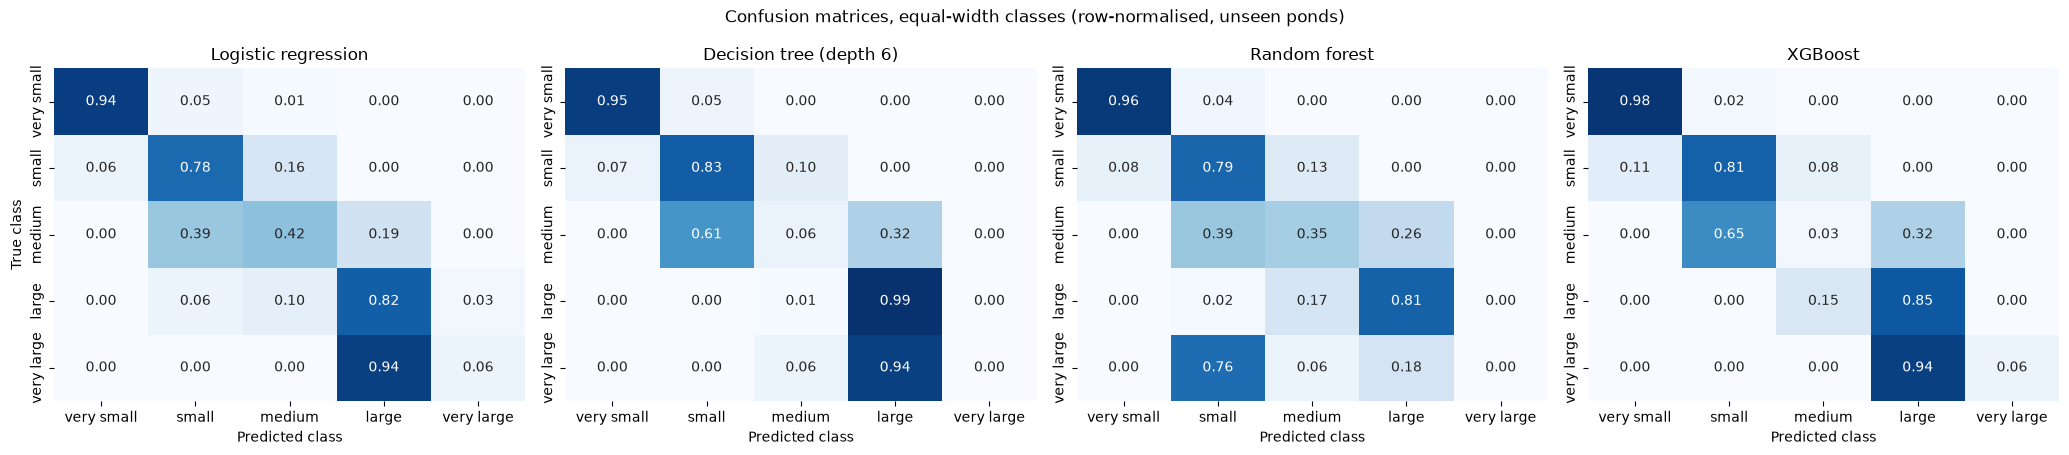

In [7]:
plot_confusion("equal-width")

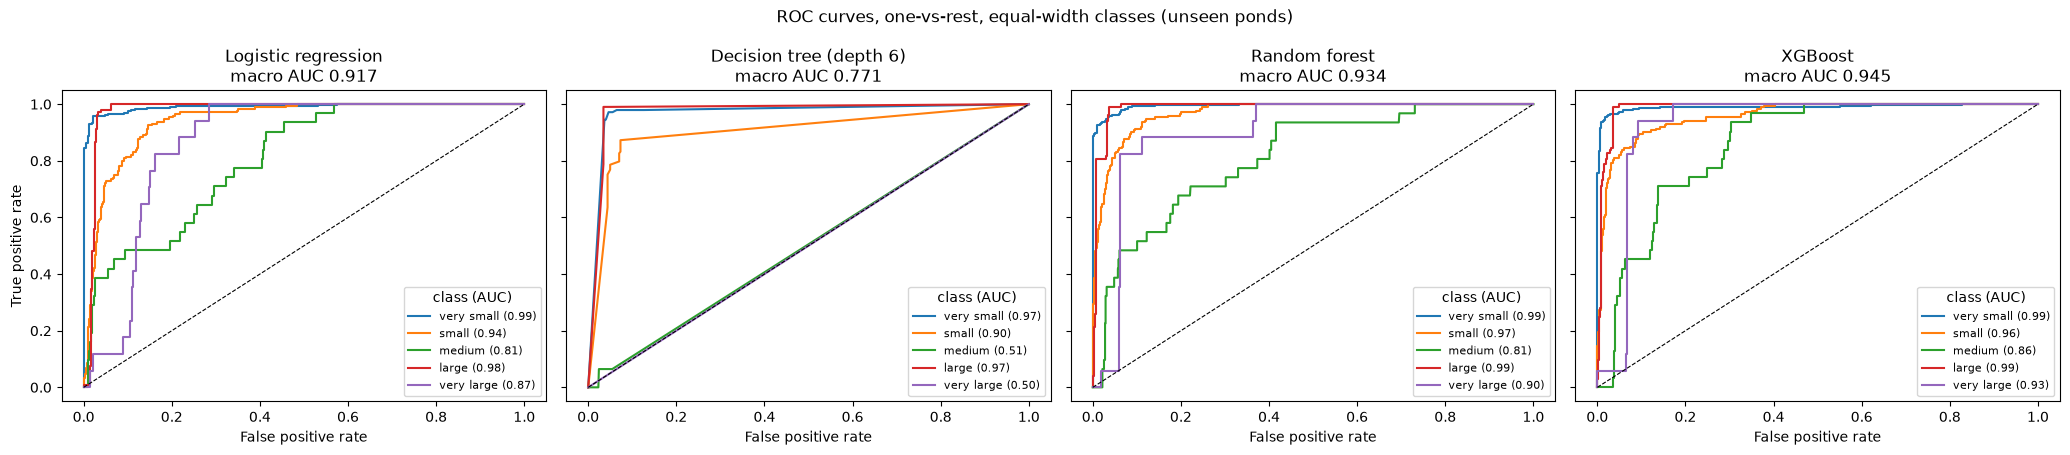

In [8]:
plot_roc("equal-width")

In [9]:
per_class_report("equal-width")

precision  recall     F1  \
model                   class                                  
Logistic regression     very small      0.980   0.944  0.962   
                        small           0.758   0.780  0.769   
                        medium          0.232   0.419  0.299   
                        large           0.794   0.817  0.806   
                        very large      0.250   0.059  0.095   
Decision tree (depth 6) very small      0.977   0.945  0.961   
                        small           0.749   0.827  0.786   
                        medium          0.091   0.065  0.075   
                        large           0.798   0.990  0.884   
                        very large      0.000   0.000  0.000   
Random forest           very small      0.973   0.959  0.966   
                        small           0.745   0.792  0.768   
                        medium          0.204   0.355  0.259   
                        large           0.884   0.808  0.844   
                        very large      0.000   0.000  0.000   
XGBoost                 very small      0.965   0.977  0.971   
                        small           0.814   0.809  0.812   
                        medium          0.032   0.032  0.032   
                        large           0.772   0.846  0.807   
                        very large      1.000   0.059  0.111   

                                    ROC AUC (one-vs-rest)  pond-days  
model                   class                                         
Logistic regression     very small                  0.991        531  
                        small                       0.942        173  
                        medium                      0.806         31  
                        large                       0.977        104  
                        very large                  0.866         17  
Decision tree (depth 6) very small                  0.969        531  
                        small                       0.905        173  
                        medium                      0.505         31  
                        large                       0.974        104  
                        very large                  0.500         17  
Random forest           very small                  0.995        531  
                        small                       0.969        173  
                        medium                      0.814         31  
                        large                       0.988        104  
                        very large                  0.903         17  
XGBoost                 very small                  0.989        531  
                        small                       0.959        173  
                        medium                      0.858         31  
                        large                       0.988        104  
                        very large                  0.929         17

### Equal-frequency classes

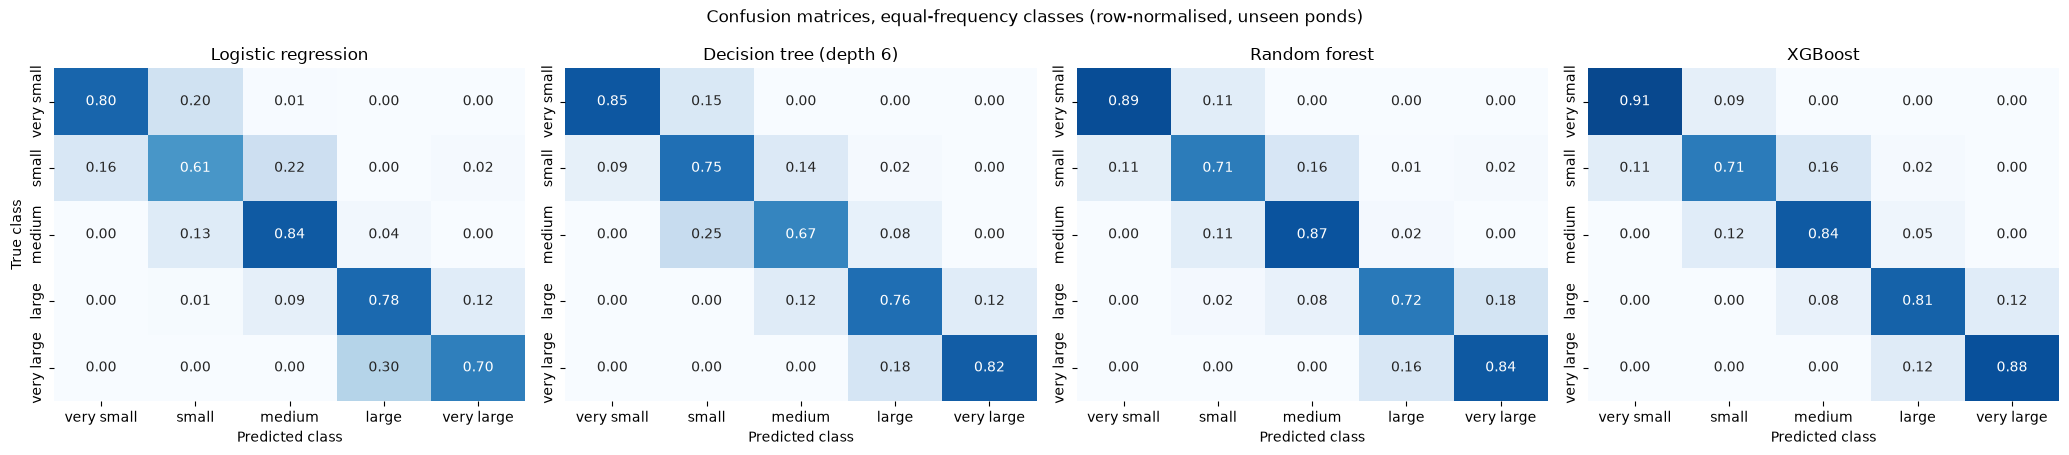

In [10]:
plot_confusion("equal-frequency")

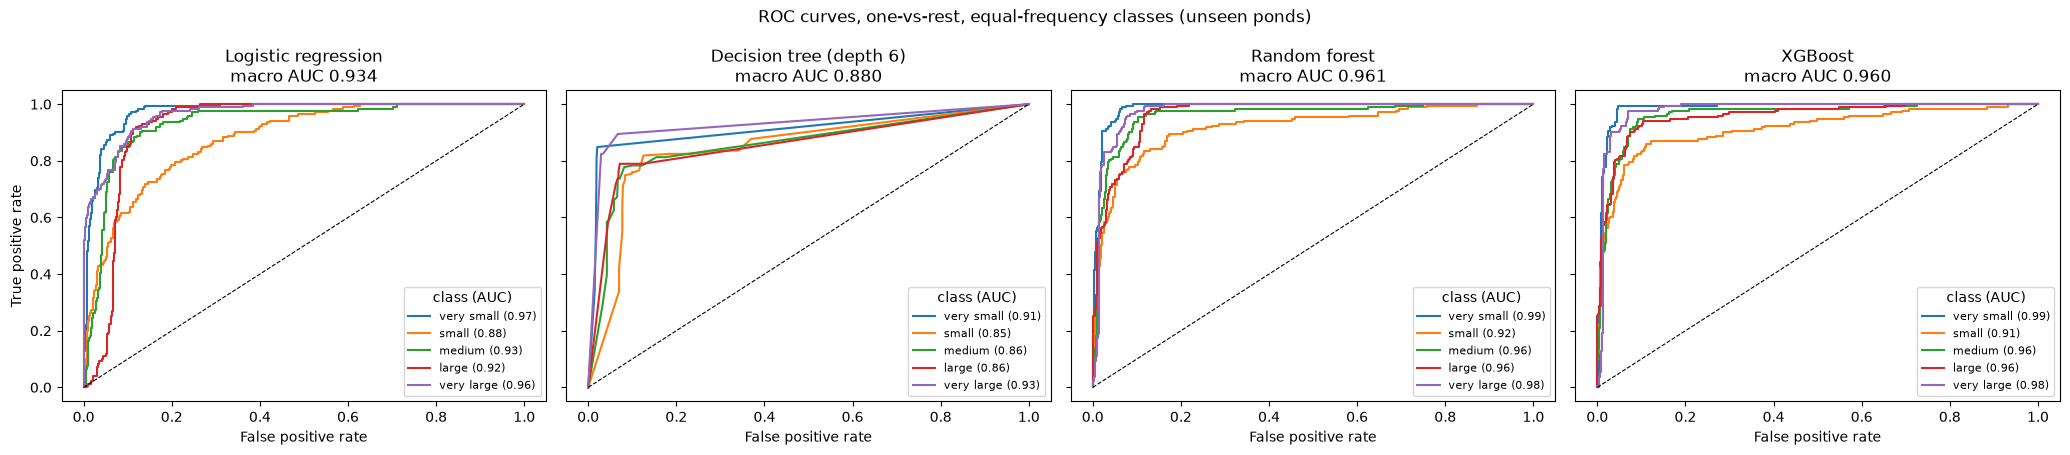

In [11]:
plot_roc("equal-frequency")

In [12]:
per_class_report("equal-frequency")

precision  recall     F1  \
model                   class                                  
Logistic regression     very small      0.835   0.797  0.815   
                        small           0.642   0.608  0.625   
                        medium          0.726   0.836  0.777   
                        large           0.696   0.778  0.735   
                        very large      0.838   0.696  0.760   
Decision tree (depth 6) very small      0.907   0.849  0.877   
                        small           0.655   0.754  0.701   
                        medium          0.719   0.673  0.695   
                        large           0.734   0.760  0.747   
                        very large      0.876   0.825  0.849   
Random forest           very small      0.895   0.890  0.892   
                        small           0.742   0.708  0.725   
                        medium          0.783   0.865  0.822   
                        large           0.794   0.719  0.755   
                        very large      0.809   0.842  0.825   
XGBoost                 very small      0.891   0.907  0.899   
                        small           0.772   0.713  0.742   
                        medium          0.781   0.836  0.808   
                        large           0.812   0.807  0.809   
                        very large      0.882   0.877  0.880   

                                    ROC AUC (one-vs-rest)  pond-days  
model                   class                                         
Logistic regression     very small                  0.974        172  
                        small                       0.879        171  
                        medium                      0.932        171  
                        large                       0.922        171  
                        very large                  0.965        171  
Decision tree (depth 6) very small                  0.911        172  
                        small                       0.847        171  
                        medium                      0.856        171  
                        large                       0.856        171  
                        very large                  0.928        171  
Random forest           very small                  0.987        172  
                        small                       0.918        171  
                        medium                      0.961        171  
                        large                       0.964        171  
                        very large                  0.977        171  
XGBoost                 very small                  0.987        172  
                        small                       0.913        171  
                        medium                      0.961        171  
                        large                       0.957        171  
                        very large                  0.979        171

**Reading the results:** compare every model with the most-frequent baseline. Neighbouring classes are the most common confusion, which is expected when the classes are cut from a continuous weight.

**Unit of analysis:** each row is one pond-day, not one fish. Class counts are numbers of pond-days and cannot be read as numbers of fish.